# 1. The damage

**The single most important thing to understand about this project:** the
detector does **not** find the insect. It finds the *feeding damage* Helopeltis
leaves on a tea leaf.

That is not a shortcut — it is what the data says. The training dataset's
bounding boxes enclose damaged leaves, not bugs. And it matches the field: the
insect is 6-8 mm and moves, while the damage stays on the leaf for days.

The consequence, stated plainly: **this model reports where the pest *was*, not
where it *is*.**

In [1]:
import json, os, sys, warnings
from pathlib import Path

# Keep library warnings out of the saved output.
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.dpi"] = 110
print("project root:", ROOT.name)

project root: TeaGuard


In [2]:
from src.pipeline import HelopeltisDamageDetector

detector = HelopeltisDamageDetector()
print("detector loaded:", detector.available)
print("input size     :", detector._imgsz, "px")
print("confidence gate:", detector.CONF_THRESHOLD)

detector loaded: True
input size     : 320 px
confidence gate: 0.25


## What it sees

Green boxes are what the detector marks. Look at *what* is inside them: leaf
lesions, not insects.

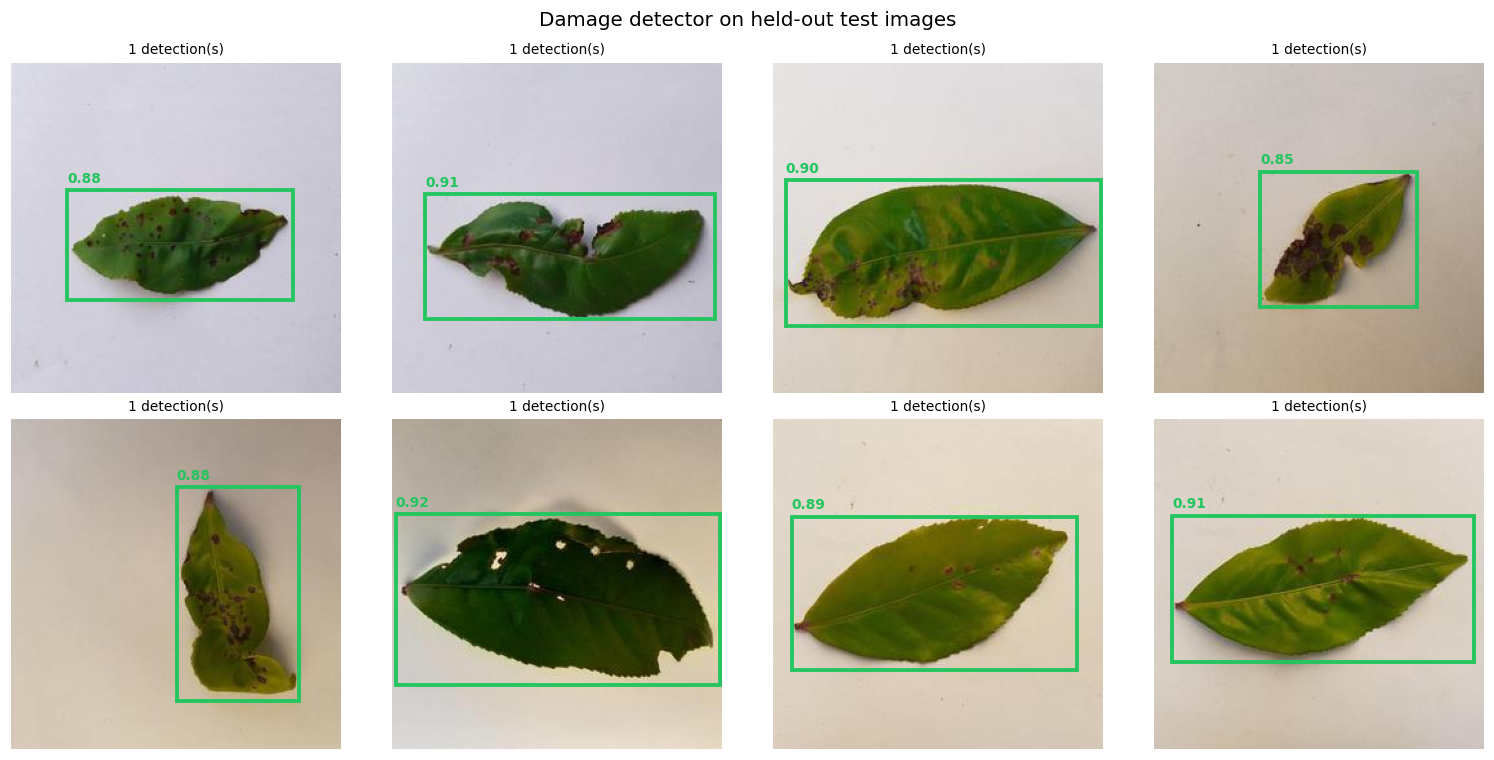

In [3]:
test_dir = ROOT / "data" / "raw" / "helopeltis" / "test" / "images"
images = sorted(test_dir.glob("*.jpg"))[:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, path in zip(axes.ravel(), images):
    img = np.array(Image.open(path).convert("RGB"))
    dets = detector.detect(img)
    ax.imshow(img)
    h, w = img.shape[:2]
    for d in dets:
        b = d.bbox
        ax.add_patch(plt.Rectangle((b.x1 * w, b.y1 * h), (b.x2 - b.x1) * w,
                                   (b.y2 - b.y1) * h, fill=False, lw=2.5,
                                   edgecolor="#22c55e"))
        ax.text(b.x1 * w, b.y1 * h - 6, f"{d.confidence:.2f}",
                color="#22c55e", fontsize=9, weight="bold")
    ax.set_title(f"{len(dets)} detection(s)", fontsize=9)
    ax.axis("off")
fig.suptitle("Damage detector on held-out test images", fontsize=13)
plt.tight_layout(); plt.show()

## The number that was a lie

For weeks this detector reported **precision 1.0**. That number was worthless,
and not because the model was bad — because of how it was measured.

The test set contained 49 images, each with exactly one ground-truth box. Every
image had damage in it. On a set like that a *false positive on a background* is
**impossible by construction**. The metric could not have come out any other way.

Meanwhile the real behaviour was: the first version of this detector fired on
**100%** of bees, ladybirds, and even insect-free leaves. It had learned to emit
a confident box on almost any image.

The fix was two-part — retrain with background images (empty labels), and
**measure on a set that can say no**.

In [4]:
metrics = json.loads((ROOT / "models" / "detector_eval.json").read_text())
for k in ["test_set", "n_positive_images", "n_background_images", "precision",
          "recall", "ap50", "specificity", "background_false_positives"]:
    print(f"{k:28s}: {metrics[k]}")

test_set                    : mixed (positives + held-out backgrounds)
n_positive_images           : 49
n_background_images         : 74
precision                   : 1.0
recall                      : 1.0
ap50                        : 1.0
specificity                 : 1.0
background_false_positives  : 0


The 74 background images are held out: other insects, spiders, butterflies,
and 22 photos of tea and foliage **with no insect at all**. None of them appear
in training.

Below are backgrounds the detector is shown. A clean image means it correctly
found nothing — which is the behaviour the first version did not have.

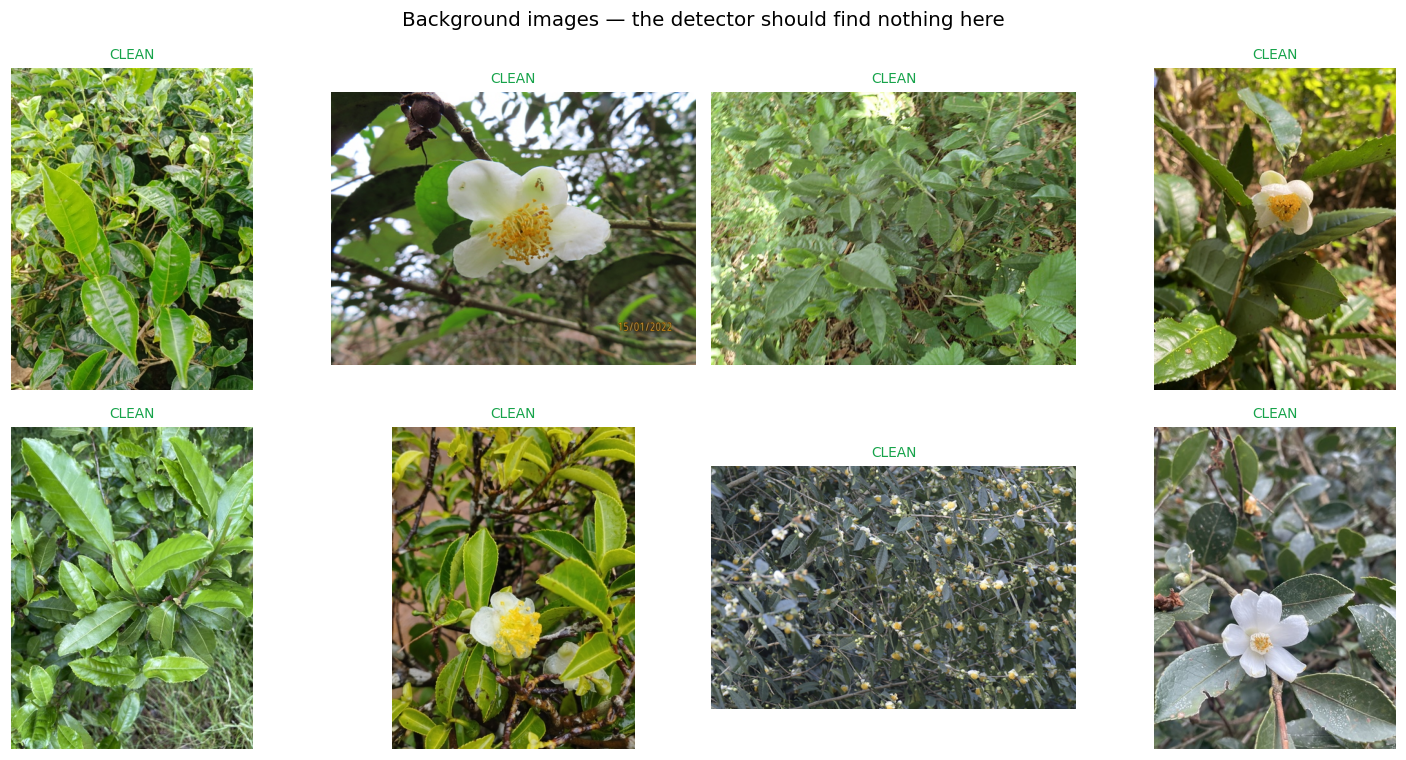

In [5]:
neg_dir = ROOT / "data" / "raw" / "helopeltis_negatives" / "test" / "images"
negatives = sorted(neg_dir.glob("*.jpg"))[:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, path in zip(axes.ravel(), negatives):
    img = np.array(Image.open(path).convert("RGB"))
    dets = detector.detect(img)
    ax.imshow(img)
    ax.set_title("CLEAN" if not dets else f"{len(dets)} FALSE POSITIVE",
                 fontsize=9, color="#16a34a" if not dets else "#dc2626")
    ax.axis("off")
fig.suptitle("Background images — the detector should find nothing here", fontsize=13)
plt.tight_layout(); plt.show()

## What this notebook does not prove

- Every image here, positive or background, comes from the internet. **No field
  photos.** The gap between an iNaturalist photo and a plantation photo is
  untested and is the largest remaining risk.
- The model has one class. It cannot tell Helopeltis damage from another pest's
  damage — if something else chewed the leaf, it would still say Helopeltis.
- Damage takes a day or more to become visible, so a clean leaf today does not
  mean a clean leaf.

Next: [2. The insect](02_the_insect.ipynb) — a second model that reads the bug
itself.